<div class="hero" style="padding:32px 36px;background:linear-gradient(120deg,#17364f,#137b7e);border-radius:18px;color:white">
<div style="font-size:12px;letter-spacing:2px;color:#bce3e1">NETWORK INTERFERENCE · STUDENT WALKTHROUGH</div>
<h1 style="color:white;font-size:32px;margin:12px 0">从一张关系网，到直接效应、溢出效应和总效应</h1>
<p style="font-size:18px;color:#eef8f7">跟着代码，理解我们在做什么</p>
<p style="color:#cce5e5">当前 iPFN 代码 · 网络干扰 · 四状态因果估计</p>
</div>

假设一家公司给部分销售员提供 AI 助手。销售员会与同事交流、协作，也可能相互竞争。
因此，一个人的业绩不仅受**自己是否获得 AI 助手**影响，也可能受**合作同事是否获得 AI 助手**影响。
这种“别人的处理影响我的结果”的现象，就是这里研究的**网络干扰（network interference）**。

我们希望回答三个问题：

1. 在同伴暴露较低的条件下，自己获得 AI 助手，平均响应会改变多少？
2. 自己已经获得 AI 助手时，同伴从低暴露变成高暴露，平均响应会改变多少？
3. 从“自己未处理、同伴低暴露”变成“自己已处理、同伴高暴露”，总体改变多少？

代码通过观测节点索引选择用于推断的结果，可以使用部分节点，也可以使用全部节点的结果。
本篇合成示例有 200 个节点，按实验配置分别选取 20、50、100 个节点的结果用于推断，并估计全部 200 个节点的效应。
这是示例中的观测数量设置；第 14 节的小图模拟示例使用全部节点的结果。

本篇按“问题、数据、公式、代码、图表”的顺序讲解。所有模型计算直接调用 `code/sparse_j/` 中的程序。

在 Jupyter 或 VS Code 中打开本 notebook，即可阅读已运行的结果，也可以从上到下重新运行。无需重新训练模型。

阅读路线：**问题 → 符号 → 网络 → 数据生成 → 高低暴露 → 四状态真值 → 观测节点选择 → 模型推断 → ITE / ATE → 基线比较 → 小图模拟例子。**


## 00 · 先认识符号：每个数组究竟装了什么？

### 网络和观测数据

| 符号 | 含义 | 程序里的名字与形状 |
|---|---|---|
| $N$ | 整张网络的节点数 | 主合成实验为 200 |
| $M$ | 选定用于推断的结果数量 | 本篇合成示例为 20、50、100；全部选取时 $M=N$ |
| $i,j$ | 节点编号，Python 从 0 开始 | `0, …, N-1` |
| $X_i$ | 节点干预前特征 | `x[N, 20]`，每人有 20 个特征 |
| $A_{ij}$ | $i,j$ 是否相连 | `adjacency[N, N]`，无向、二元、无自环 |
| $d_i=\sum_j A_{ij}$ | 节点的邻居数 | 由邻接矩阵求和；要求每人至少有一个邻居 |
| $T_i\in\{0,1\}$ | 自己是否接受处理 | `treatment[N]` |
| $O$ | 选定用于推断的节点索引集合 | `observed_indices[M]` |
| $Y_O$ | 所选节点的观测结果 | `outcomes_observed[M]`；顺序与 $O$ 一一对应 |

例如 `observed_indices=[8,2,5]`、`outcomes_observed=[1.4,-0.2,0.7]` 表示：节点 8 的结果为 1.4，节点 2 为 −0.2，节点 5 为 0.7。
**索引不必排序，但结果的顺序必须对应。** 未选入本次推断的结果不传入预测函数，也不用 0 代替。

### 暴露、响应与效应

| 符号 | 含义 | 注意 |
|---|---|---|
| $K_i=\sum_j A_{ij}T_j$ | 接受处理的邻居人数 | 不包含节点自己 |
| $E_i=K_i/d_i$ | 接受处理的邻居比例 | 例如 3/4 = 0.75 |
| $S_i=\mathbb 1\{E_i>0.5\}$ | 高／低暴露状态 | 恰好一半属于低暴露 |
| $t,s$ | 查询时指定的自身处理和同伴状态 | 与实际观察到的 $T_i,S_i$ 区分 |
| $\mu_i(t,s)$ | 四种状态下的设计平均响应真值 | 对该状态内的邻居分配按处理设计取平均 |
| $\widehat\mu_i(t,s)$ | 模型估计的平均响应 | 帽子表示估计值 |
| ITE | 节点层面的状态对比 | 这里是四状态平均响应的差，不是某次噪声的差 |
| ATE | 对全部节点的 ITE 取平均 | 分母是 $N$，不是 $M$ |

下文统一用 $A$ 表示邻接矩阵，$T$ 表示处理。四状态顺序固定为 **`00, 01, 10, 11`**：第一位看自己，第二位看同伴。

### 读模型部分才需要的符号

$h_i$ 表示由特征得到的三维表示；$\overline h_i$ 是邻居表示的平均；
$J_i=d_i^{-1}\sum_j A_{ij}T_jh_j$ 同时记录“哪些邻居被处理”以及“他们具有什么特征”。
这里的向量 $J_i$ 和模型名 **iPFN J** 是两件事。结构方程中的 $\gamma_i$ 是节点溢出系数；模型中的先验膨胀强度在本文另记为 $\lambda$，避免混淆。


## 01 · 运行准备：保留完整文件夹即可

推荐 Python 3.12。先在本项目根目录执行下面命令，再打开本 notebook：

```bash
python3.12 -m venv .venv
source .venv/bin/activate
python -m pip install -r requirements-notebook.txt
python -m jupyterlab
```

Windows 可用 `py -3.12 -m venv .venv`，PowerShell 的激活命令为 `.venv\Scripts\Activate.ps1`。
VS Code 中选择对应的 `.venv` Python 内核。系统自带的旧版 Python 不一定满足 PyTorch 的版本要求。

下面的准备单元定位项目、加载依赖、固定 CPU 线程数，并建立本次运行的临时目录。
图表和表格直接显示在 notebook 中；用于演示文件读写的中间文件保存在临时目录。模型权重以只读方式加载。


In [1]:
from pathlib import Path
import sys, hashlib, time, platform, tempfile, importlib.metadata as metadata

PROJECT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                if (p / "code/sparse_j/predict_current.py").is_file()), None)
if PROJECT is None:
    raise RuntimeError("请从完整项目的根目录或 notebooks 目录打开本文件。")
CODE = PROJECT / "code/sparse_j"
if str(CODE) not in sys.path:
    sys.path.insert(0, str(CODE))

import numpy as np
import pandas as pd
import torch
import networkx as nx
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from threadpoolctl import threadpool_limits
from predict import CHECKPOINT_SHA256
from predict_current import load_current_model
from regional_inference import regional_gate
from pfn_social.contracts import arm_mean_exposure, conditional_count_weights
from pfn_social.phase6_limited_outcomes import generate_mechanism, make_observed_draw, configuration as family_configuration
from pfn_social.phase3_hierarchical import structural_outcome
from pfn_social.sparse_frozen_gaussian import validate_factual_inputs
from benchmark import configuration, load_methods, predict_method, DEFAULT_METHODS

torch.set_num_threads(1)
THREAD_LIMIT = threadpool_limits(limits=1)
_temporary_results = tempfile.TemporaryDirectory(prefix="ipfn_walkthrough_")
RESULTS = Path(_temporary_results.name)
COLORS = ["#147d85", "#d58a36", "#5969a5", "#b35e76"]
EFFECTS = ["Direct", "Spillover", "Total"]
plt.rcParams.update({"figure.dpi": 120,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.facecolor": "#f6f8fa", "figure.facecolor": "white",
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.prop_cycle": plt.cycler(color=COLORS)})

def table(frame, digits=4):
    display(HTML(frame.to_html(index=False, float_format=lambda v: f"{v:.{digits}f}",
                              na_rep="—", border=0, classes="student-table")))

def show(fig):
    plt.show()
    plt.close(fig)

def effects(mu):
    # 与 predict_current.py 中的列顺序和三种对比完全一致。
    return np.stack((mu[:, 2]-mu[:, 0], mu[:, 3]-mu[:, 2], mu[:, 3]-mu[:, 0]), axis=-1)

versions = {name: metadata.version(name) for name in
            ["numpy", "torch", "scipy", "networkx", "torch-geometric", "threadpoolctl", "matplotlib", "pandas"]}
table(pd.DataFrame({"依赖": ["Python", *versions], "本次版本": [platform.python_version(), *versions.values()]}))


依赖,本次版本
Python,3.12.14
numpy,2.1.3
torch,2.8.0
scipy,1.15.3
networkx,3.4.2
torch-geometric,2.6.1
threadpoolctl,3.5.0
matplotlib,3.10.0
pandas,2.3.3


### 一份数据怎样走过程序？

| 顺序 | 我们在做什么 | 输入 → 输出 | 当前源码 |
|---|---|---|---|
| 1 | 规定一组模拟机制 | 图类型、特征分布、系数先验 → 网络与潜在响应规律 | [phase5_large_network.py](../code/sparse_j/pfn_social/phase5_large_network.py) |
| 2 | 在同一机制下分配处理、生成结果 | 固定图和规律 → 一次 $T,Y$ | `make_repeat`、[structural_outcome](../code/sparse_j/pfn_social/phase3_hierarchical.py) |
| 3 | 按实验设置选取观测节点 | 完整模拟数据 → 五个观测数组 | [phase6_limited_outcomes.py](../code/sparse_j/pfn_social/phase6_limited_outcomes.py) |
| 4 | 加载冻结模型 | 已选权重与区域设置 → 当前预测器 | [predict_current.py](../code/sparse_j/predict_current.py) |
| 5 | 条件化并查询四状态 | 五个数组 → `arm_means[N,4]` | [sparse_frozen_gaussian.py](../code/sparse_j/pfn_social/sparse_frozen_gaussian.py) |
| 6 | 形成因果效应 | 四个平均响应 → 三种 ITE、ATE | `predict_current.py` / `pack` |
| 7 | 对照真值评测 | 预测与模拟器真值 → 误差、支持标记 | [benchmark.py](../code/sparse_j/benchmark.py) |

可以把它看成两条线：**模拟器保管真值，预测器只拿观测数据**。直到评测时，两条线才汇合。
这也是后面把 `inputs` 与 `truth_mu` 分开存放的原因。


## 02 · 当前实验到底研究哪几种网络？

我们先从一份具体任务读起：`family=0, mechanism=0, repeat=0, M=50`。
它有 200 个节点；第一类机制使用带环骨架的 WS 型图。其他机制还包括更密的 WS、ER 型、SBM 型图，
以及噪声强度和特征表示变化。下表直接从代码读取，避免把旧教程的设定带进来。

**图的生成方式有一个细节**：程序先连成一个环，再添加或重连其他边，因此每个节点至少有邻居。
代码里的 ER／SBM 是带环骨架的变体，不能简单理解成没有任何额外条件的标准 ER／SBM 随机图。

“机制”固定图、特征、隐藏系数和四状态真值；“重复”在同一机制下重新抽取处理与噪声。
不同重复不是不同的独立机制。


In [2]:
FAMILY_ID, MECHANISM_ID, REPEAT_ID, M_OBSERVED = 0, 0, 0, 50
FOCAL_NODE = 0
family_rows = []
for family_id in range(7):
    cfg = family_configuration(family_id)
    s = cfg.setting
    family_rows.append({"family": family_id, "节点 N": s.n, "图": s.graph,
                       "度数参数": s.degree, "噪声标准差": s.noise_sd, "表示": s.representation})
table(pd.DataFrame(family_rows))

mechanism = generate_mechanism(FAMILY_ID, MECHANISM_ID)
observed_rows, _ = make_observed_draw(mechanism, REPEAT_ID)
chosen = next(row for row in observed_rows if row["m_observed"] == M_OBSERVED)
inputs = {key: value.numpy().copy() for key, value in chosen["batch"].items()}
validate_factual_inputs(**inputs)
truth_mu = mechanism.parent.truth.copy()  # 只供解释模拟器、核对和评测。
A, X, T = inputs["adjacency"], inputs["x"], inputs["treatment"]
ids, y = inputs["observed_indices"], inputs["outcomes_observed"]
N = len(X)
degree = A.sum(1).astype(int)
G = nx.from_numpy_array(A)
print(f"本篇任务：{chosen['context_id']}；节点={N}；观测结果={len(ids)}；特征维数={X.shape[1]}")
print(f"实际边数={G.number_of_edges()}；度数范围={degree.min()}—{degree.max()}；连通分量={nx.number_connected_components(G)}")


family,节点 N,图,度数参数,噪声标准差,表示
0,200,ws,4,1.0000,shared_nonlinear
1,200,ws,4,2.0000,shared_nonlinear
2,200,ws,8,1.0000,shared_nonlinear
3,200,er,4,1.0000,shared_nonlinear
4,200,sbm,4,1.0000,shared_nonlinear
5,200,ws,4,1.0000,unshared_nonlinear
6,200,ws,8,1.0000,shared_linear


本篇任务：f0_m0_r0_observed50；节点=200；观测结果=50；特征维数=20
实际边数=400；度数范围=3—6；连通分量=1


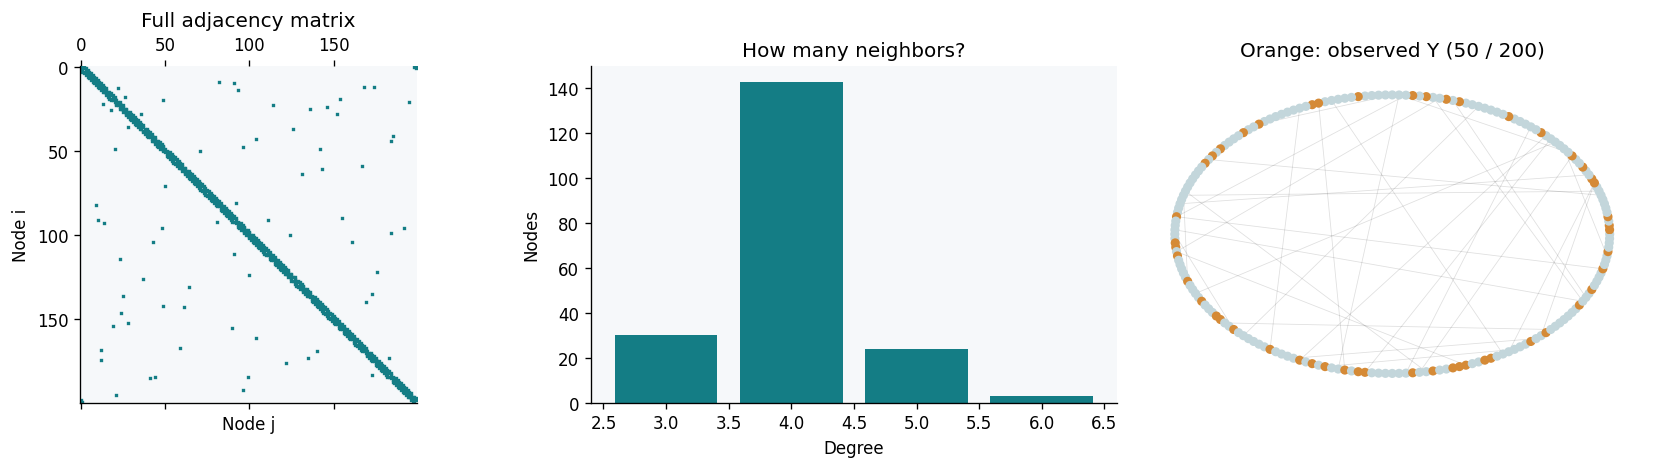

In [3]:
observed_mask = np.zeros(N, dtype=bool)
observed_mask[ids] = True
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), constrained_layout=True)
axes[0].spy(A, markersize=1.0, color=COLORS[0])
axes[0].set(title="Full adjacency matrix", xlabel="Node j", ylabel="Node i")
axes[1].hist(degree, bins=np.arange(degree.min()-.5, degree.max()+1.5), color=COLORS[0], rwidth=.82)
axes[1].set(title="How many neighbors?", xlabel="Degree", ylabel="Nodes")
pos = nx.circular_layout(G)
nx.draw_networkx_edges(G, pos, ax=axes[2], alpha=.12, width=.5)
nx.draw_networkx_nodes(G, pos, ax=axes[2], node_size=20,
                       node_color=np.where(observed_mask, COLORS[1], "#c3d6db"))
axes[2].set_title(f"Orange: observed Y ({len(ids)} / {N})")
axes[2].axis("off")
show(fig)


**读图**：左图展示完整关系网的邻接矩阵；中图展示每人有多少邻居；右图的橙色点是本次选取结果用于推断的节点。
灰色点的结果未用于这次推断，但它们的 $X,T$ 和连接关系仍包含在输入中。**选择部分结果不会删去网络中的节点。**
如果只保留橙色点及其子图，就会改变真实邻居集合、暴露比例和预测目标。


## 03 · DGP：模拟器怎样生成一份数据？

DGP 是 data-generating process，即“数据生成过程”。我们先规定一套规律制造数据，
这样才知道真正的因果效应是多少，能够检查估计方法算得准不准。它不是由现实销售数据得出的经验定律。

### 第一步：固定这份任务的特征和隐藏响应规律

主实验的原始特征为 20 维。每个机制先抽取一个共享的总体均值向量，再给每个节点加上自身差异：

$$c\sim\mathcal N(0,0.8^2I_{20}),\qquad X_i=c+0.6\xi_i,\quad \xi_i\sim\mathcal N(0,I_{20}).$$

模拟器用一个二维投影 $z_i=X_iP$ 构造三维隐藏特征。共享非线性机制为

$$h_i=\left[\tanh(1.5z_{i1}),\ \sin(1.5z_{i2}),\ \tanh(z_{i1}z_{i2})\right].$$

线性机制改用线性组合；不共享的机制会换投影方向。每份机制再从代码定义的高斯先验抽取 25 个系数。
这些系数共同决定基线响应 $b_i$、直接项 $\tau_i$、暴露项 $\gamma_i$、交互项 $\eta_i$，以及邻居身份项 $u,v$。
这里的真系数和真隐藏表示只属于模拟器，不能交给估计器。

### 第二步：抽处理、算同伴暴露、生成连续结果

$$T_i\overset{\mathrm{iid}}\sim\operatorname{Bernoulli}(0.5),\qquad
E_i=\frac{\sum_j A_{ij}T_j}{d_i},\qquad
J_i=\frac{\sum_j A_{ij}T_jh_j}{d_i}.$$

代码中的完整响应方程为

$$Y_i=b_i+\tau_iT_i+(\gamma_i+\eta_iT_i)E_i
       +u^\top J_i+T_i v^\top J_i+\epsilon_i,
\qquad\epsilon_i\sim\mathcal N(0,\sigma^2).$$

| 部分 | 在销售员例子中怎样理解 |
|---|---|
| $b_i$ | 不含处理的基线响应，包含本人和邻居的特征影响 |
| $\tau_iT_i$ | 自己获得工具的贡献 |
| $\gamma_iE_i$ | 同伴处理比例的贡献 |
| $\eta_iT_iE_i$ | 自己的处理与同伴暴露共同作用 |
| $u^\top J_i+T_i v^\top J_i$ | 同样比例下，被处理的是哪些特征的邻居也可能重要 |
| $\epsilon_i$ | 这次观测的随机噪声 |

因此，同样是“一半邻居接受处理”，如果被处理的邻居不同，响应仍可能不同。
下面只在模拟器解释环节展开这条方程，逐项核对原函数；之后预测时仍只使用五个观测数组。


node,baseline,own,exposure,interaction,neighbor_identity,own_identity
0,-1.0565,-0.0344,0.0000,-0.0000,0.0000,0.0000
1,-0.3403,-0.0000,-0.2336,-0.0000,-0.0690,0.0000
2,-0.9788,-0.0000,-0.0599,-0.0000,-0.0690,0.0000
3,-0.8537,-0.0000,-0.0816,-0.0000,-0.1135,0.0000
4,-0.5946,-0.0000,-0.0048,-0.0000,-0.2010,0.0000
5,-0.6787,-0.7072,-0.3156,-0.1897,-0.1687,0.0686
6,-0.4761,-0.7184,-0.1042,-0.1187,-0.1946,0.0429
7,-0.4645,-0.7243,-0.0028,-0.0896,-0.2010,0.0309


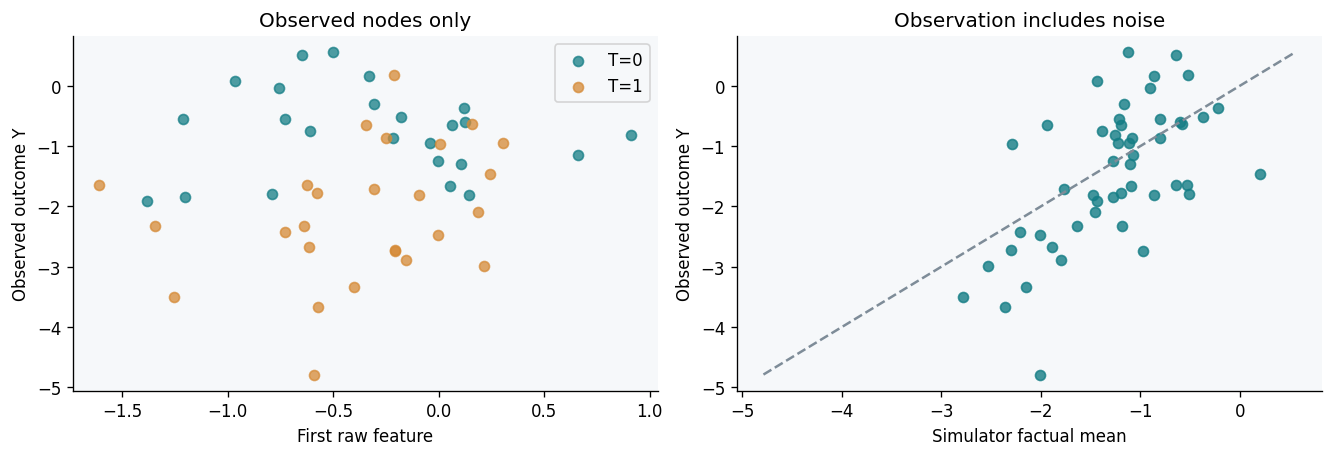

In [4]:
sim = mechanism.parent
h, beta = sim.h, sim.coefficients
b, tau, gamma_i, eta_i = sim.components.T
E = A @ T / degree
J = A @ (T[:, None] * h) / degree[:, None]
contributions = pd.DataFrame({
    "node": np.arange(N), "baseline": b, "own": T*tau,
    "exposure": gamma_i*E, "interaction": eta_i*T*E,
    "neighbor_identity": J @ beta[19:22], "own_identity": T*(J @ beta[22:25])})
structural_mean = structural_outcome(sim, T)
np.testing.assert_allclose(contributions.drop(columns="node").sum(axis=1), structural_mean, atol=1e-10)
table(contributions.head(8))

# 仅在已观测节点上展示 Y；完整结构均值是模拟器的诊断信息。
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7), constrained_layout=True)
for treatment in (0, 1):
    select = T[ids] == treatment
    axes[0].scatter(X[ids[select], 0], y[select], alpha=.75, label=f"T={treatment}")
axes[0].set(title="Observed nodes only", xlabel="First raw feature", ylabel="Observed outcome Y")
axes[0].legend()
axes[1].scatter(structural_mean[ids], y, color=COLORS[0], alpha=.8)
limits = [min(structural_mean[ids].min(), y.min()), max(structural_mean[ids].max(), y.max())]
axes[1].plot(limits, limits, "--", color="#7e8c98")
axes[1].set(title="Observation includes noise", xlabel="Simulator factual mean", ylabel="Observed outcome Y")
show(fig)


左图的两组观测用于认识数据；把它们的平均值相减，并不能直接给出本篇定义的三种节点效应。
右图中点偏离虚线，是因为观测结果包含噪声。后面评测比较的是**状态平均响应的预测与真值**，
不是要求预测器把本次噪声也逐个猜中。


## 04 · 什么叫高暴露、低暴露？

看节点小李时，有两个独立的问题：小李自己有没有接受处理？小李的邻居中有多少人接受处理？
前者是 $T_i$，后者先计算比例 $E_i$，再分为状态 $S_i$：

$$S_i=\mathbb 1\{K_i>\lfloor d_i/2\rfloor\}=\mathbb 1\{E_i>0.5\}.$$

假设小李有 4 名邻居：

| 接受处理的邻居数 | 暴露比例 | 状态 |
|---:|---:|---|
| 0 | 0.00 | 低暴露 |
| 1 | 0.25 | 低暴露 |
| 2 | 0.50 | **低暴露，恰好一半仍归这里** |
| 3 | 0.75 | 高暴露 |
| 4 | 1.00 | 高暴露 |

高暴露不表示业绩高，也不是“结果被观察到了”。它只描述邻居的处理比例。
由于图没有自环，计算本人的暴露时不数本人。
下面统计当前任务四种事实状态的人数，并单独列出选入本次推断的节点数。


In [5]:
K = (A @ T).astype(int)
S = (K > degree // 2).astype(int)
state = 2*T.astype(int) + S  # 00,01,10,11
state_rows = [{"状态": f"{t}{s}", "自身处理": t, "同伴高暴露": s,
               "全部节点": int((state == 2*t+s).sum()),
               "观测结果节点": int(((state == 2*t+s) & observed_mask).sum())}
              for t, s in [(0,0), (0,1), (1,0), (1,1)]]
table(pd.DataFrame(state_rows))
factual_view = pd.DataFrame({"节点": ids[:10], "T": T[ids[:10]].astype(int),
    "度数": degree[ids[:10]], "处理邻居数 K": K[ids[:10]], "比例 E": E[ids[:10]],
    "高暴露 S": S[ids[:10]], "观测 Y": y[:10]})
table(factual_view)


状态,自身处理,同伴高暴露,全部节点,观测结果节点
00,0,0,57,16
01,0,1,34,8
10,1,0,60,16
11,1,1,49,10


节点,T,度数,处理邻居数 K,比例 E,高暴露 S,观测 Y
83,1,4,3,0.7500,1,-2.8888
172,0,4,4,1.0000,1,-0.7504
138,0,3,1,0.3333,0,-0.9468
61,0,3,1,0.3333,0,-1.8181
183,0,4,4,1.0000,1,0.0744
74,1,4,2,0.5000,0,-0.8644
62,0,4,2,0.5000,0,-0.6511
4,0,4,2,0.5000,0,-0.5545
105,1,4,2,0.5000,0,-3.6621
16,0,3,0,0.0000,0,-0.5108


## 05 · 为什么一个“低暴露”状态还要取平均？

“低暴露”是一组处理分配，不是一个唯一比例。4 名邻居时，0、1、2 人被处理都属于低暴露，
但三种人数情况的概率不同。当前设计下各邻居独立以 0.5 的概率接受处理，所以

$$K_i\sim\operatorname{Binomial}(d_i,0.5).$$

把属于指定状态的概率留下，再归一化，就得到条件权重：

$$P(K_i=k\mid S_i=s)=
\frac{\binom{d_i}{k}0.5^{d_i}\,\mathbb 1\{k\in\mathcal K_s\}}
{\sum_{\ell\in\mathcal K_s}\binom{d_i}{\ell}0.5^{d_i}},\qquad
e_{i,s}=\mathbb E[E_i\mid S_i=s].$$

例如 $d_i=4$，低暴露的权重为 $1/11,4/11,6/11$，高暴露的权重为 $4/5,1/5$。
因此平均暴露分别为 $4/11\approx0.364$ 和 $0.8$，**不是固定取 0 和 1，也不是把状态里的比例等权平均。**

四状态响应先指定本人 $T_i=t$，再对 $S_i=s$ 内的邻居处理分配取这个设计平均。
它比较的是定义明确的两种同伴环境，不能理解成“所有邻居都未处理／都已处理”。


K,E=K/4,低暴露条件概率,高暴露条件概率
0,0.0000,0.0909,0.0000
1,0.2500,0.3636,0.0000
2,0.5000,0.5455,0.0000
3,0.7500,0.0000,0.8000
4,1.0000,0.0000,0.2000


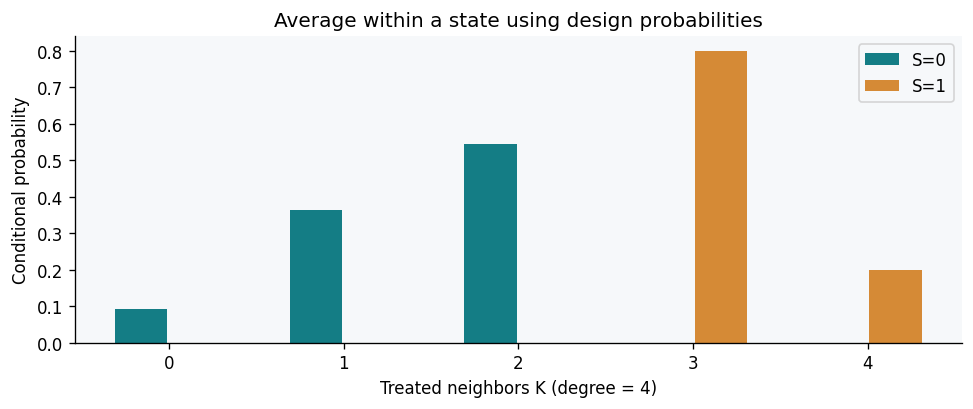

平均暴露： {'S=0': 0.36363636363636365, 'S=1': 0.8}


In [6]:
toy_degree = 4
counts = np.arange(toy_degree + 1)
weights = [conditional_count_weights(toy_degree, .5, s) for s in (0, 1)]
table(pd.DataFrame({"K": counts, "E=K/4": counts/4,
                    "低暴露条件概率": weights[0], "高暴露条件概率": weights[1]}))
fig, ax = plt.subplots(figsize=(8, 3.3), constrained_layout=True)
for s in (0, 1):
    ax.bar(counts + (s-.5)*.32, weights[s], .3, label=f"S={s}", color=COLORS[s])
ax.set(xticks=counts, xlabel="Treated neighbors K (degree = 4)", ylabel="Conditional probability",
       title="Average within a state using design probabilities")
ax.legend()
show(fig)
print("平均暴露：", {f"S={s}": arm_mean_exposure(4, .5, s) for s in (0,1)})


## 06 · 四个响应真值怎样得到？

固定当前机制的 $A,X,h,\beta$。因为同一人数条件下邻居具有可交换的处理分配概率，
有 $\mathbb E[J_i\mid S_i=s]=e_{i,s}\overline h_i$。将它代入第 03 节方程，噪声取均值 0，得到

$$\mu_i(t,s)=b_i+t\tau_i+
e_{i,s}\left[\gamma_i+t\eta_i+\overline h_i^\top(u+t v)\right].$$

| 列号 | 状态 | 询问什么 |
|---:|---|---|
| 0 | 00 | 自己未处理，同伴低暴露 |
| 1 | 01 | 自己未处理，同伴高暴露 |
| 2 | 10 | 自己已处理，同伴低暴露 |
| 3 | 11 | 自己已处理，同伴高暴露 |

下面用公式重算一遍，核对生成器保存的真值。**这一步是检查模拟器；预测模型不会读入这张表。**
真实数据中通常没有这四个真值，所以不能像模拟实验一样直接计算误差。


In [7]:
hbar = A @ h / degree[:, None]
mean_exposures = np.array([[arm_mean_exposure(int(d), .5, s) for s in (0,1)] for d in degree])
formula_truth = np.column_stack([
    b + t*tau + mean_exposures[:, s] * (gamma_i+t*eta_i+hbar @ (beta[19:22]+t*beta[22:25]))
    for t, s in [(0,0), (0,1), (1,0), (1,1)]])
np.testing.assert_allclose(formula_truth, truth_mu, rtol=1e-10, atol=1e-10)
table(pd.DataFrame({"节点": np.arange(6), **{f"真值 μ{arm}": truth_mu[:6,k]
                      for k, arm in enumerate(["00","01","10","11"])}}))
print("公式与生成器真值一致。")


节点,真值 μ00,真值 μ01,真值 μ10,真值 μ11
0,-1.1194,-1.1949,-1.1599,-1.2428
1,-0.8580,-1.4793,-1.2394,-1.9583
2,-1.2127,-1.4935,-2.3646,-2.7766
3,-1.1318,-1.4655,-2.5167,-3.0157
4,-0.7911,-1.0268,-1.7732,-2.0712
5,-1.0728,-1.5458,-1.8617,-2.4327


公式与生成器真值一致。


## 07 · 怎样选择观测节点，模型接收哪些数据？

本例保留整张 200 节点图，选取 50 个节点的结果用于推断。
模型利用所有节点的协变量、处理和图结构构造特征，使用所选节点的结果进行似然条件化，再查询全部节点。

公开推断入口由 `observed_indices` 指定所选节点。当索引覆盖全部节点、`outcomes_observed` 提供对应的全部结果时，便是 $M=N$ 的全观测输入。
本篇合成实验的生成器固定比较 20、50、100 三档观测数量；这项实验配置与公开推断入口支持全观测并不冲突。

| 数据 | 是否覆盖全部节点 | 用途 |
|---|---|---|
| $X,A,T$ | 是 | 计算完整网络上的表示、邻居聚合和事实暴露 |
| $Y_O$ | 按索引选择 $M$ 个；可取 $M=N$ | 提供这份任务的观测证据 |
| 四状态查询 | 是，$N\times4$ 个 | 要估计所有节点的四个平均响应 |
| 真系数、隐藏特征和真值 | 预测器不可见 | 只在模拟器与评测环节使用 |

观察索引由独立随机流预先生成，与处理和结果无关；20、50、100 是同一排列的前缀，所以三个观测集合嵌套。
同一机制的重复使用同一观察集合，重新抽处理和噪声。这些掩码与重复不能当成额外的独立机制来扩大样本量。

代码用 `outcomes_observed[M]` 按索引顺序提供选定结果；选取部分结果时无需补零，选取全部结果时其长度为 $N$。
下表显示本篇真正传入模型的五项内容。


In [8]:
table(pd.DataFrame([{"键": key, "形状": str(value.shape), "dtype": str(value.dtype)}
                    for key,value in inputs.items()]))
assert set(inputs) == {"x","adjacency","treatment","observed_indices","outcomes_observed"}
mask_sets = [set(row["batch"]["observed_indices"].tolist()) for row in observed_rows]
assert mask_sets[0] < mask_sets[1] < mask_sets[2]
table(pd.DataFrame([{"观测结果 M": row["m_observed"], "查询节点 N": N,
                     "观测比例": row["m_observed"]/N, "context": row["context_id"]}
                    for row in observed_rows]))
np.savez_compressed(RESULTS / "factual_input.npz", **inputs)


键,形状,dtype
x,"(200, 20)",float32
adjacency,"(200, 200)",float32
treatment,"(200,)",float32
observed_indices,"(50,)",int64
outcomes_observed,"(50,)",float32


观测结果 M,查询节点 N,观测比例,context
20,200,0.1000,f0_m0_r0_observed20
50,200,0.2500,f0_m0_r0_observed50
100,200,0.5000,f0_m0_r0_observed100


## 08 · 当前 iPFN 在做什么？先看整体，再看公式

当前发布包已经包含选定的 **J 模型权重**。在线时不再优化这些神经网络参数。
它使用冻结的表示和高斯系数先验，根据本次提供的观测结果进行后验更新，再回答四状态查询。

可以把它理解为：模型事先学到一组“可能的响应规律”；拿到这一张图上选定的观测结果后，
根据观测证据调整这些规律的可信度，综合给出响应预测。

### 8.1 图环境编码：先从 $X,A$ 提取信息

冻结的训练变换把 20 维原始特征标准化并投影到二维 $z_i$。
J 编码器组合五个 Hermite 特征、$Wz$、$W^2z$、全体节点的 $z$ 均值以及 $\log(1+d_i)$，合计 12 维，
其中 $W_{ij}=A_{ij}/d_i$。这些信息进入 `12 → 64 → 3` 的 Tanh 网络，得到三维表示。
编码器只读取干预前的 $X,A$。

### 8.2 两种表示，各自形成响应回归项

模型同时保留“学到的三维表示”和“原始二十维特征”两条分支。
对任一表示 $r_i$，构造

$$\phi_i=[1,r_i,\overline r_i,\ T_i(1,r_i),\ E_i(1,r_i),\ T_iE_i(1,r_i),\ J_i^{(r)},\ T_iJ_i^{(r)}].$$

三维分支得到 25 项，二十维分支得到 144 项。这对应源码 `design()` 的排列。
构造事实行时用观测到的 $T,E,J$；构造查询行时改用指定 $t$、条件平均暴露 $e_{i,s}$ 与 $e_{i,s}\overline r_i$。

### 8.3 根据选定结果更新，给四个查询打分

在每个“表示分支 × 噪声方差”的组合中，使用高斯线性模型。
记所选节点对应的设计矩阵为 $F_O$，四状态查询行为 $q_i(t,s)$，则后验均值的核心形式是

$$\widehat\mu_i(t,s)=q_i(t,s)m_0+
q_i(t,s)\Sigma_\lambda F_O^\top
(F_O\Sigma_\lambda F_O^\top+\sigma^2I_M)^{-1}(Y_O-F_Om_0).$$

代码用 Cholesky 等稳定的线性代数计算，不直接按上式显式求逆。
目标对齐先验沿两个平均查询对比方向调整协方差：

$$\Sigma_\lambda=\Sigma+\lambda\Sigma C^\top(C\Sigma C^\top)^{-1}C\Sigma,\quad\lambda\ge0.$$

$C$ 的两行是全部节点上 direct 和 spillover 的平均查询对比，只依赖查询设计，不读取结果真值。
本篇仅说明其作用：先验对我们关心的效应方向保留一定灵活性；冻结的 $\lambda$ 不在每个测试任务重新调参。

最后将 **2 个表示 × 4 个噪声方差 = 8 个组合**按观测边际似然和先验权重加权。
这是观测证据决定的后验加权。四个处理臂使用同一组混合权重，以保持响应对比的一致性。

**当前推断入口返回四个响应的均值。** 后面用这些均值计算 ITE 和 ATE。


## 09 · 加载权重并执行推断：调用当前模型

`load_current_model()` 读取选定的 J 权重、两个核模型和固定区域设置。
当 $N\ge50$ 或结果不是全观测时，公开入口直接走冻结 J。
当 $N<50$ 且 $M=N$ 时，走小网络的固定校准组合；第 14 节再看这个分支。

当前任务 $N=200,M=50$，所以走冻结 J。没有训练循环，也没有把真值塞进输入。
注意：**神经网络权重冻结，并不表示预测对新观测结果没有反应**；传入的 $Y_O$ 会通过后验更新影响输出。


In [9]:
checkpoint = CODE / "models/iPFN_J.pt"
digest = hashlib.sha256(checkpoint.read_bytes()).hexdigest()
assert digest == CHECKPOINT_SHA256
current_model = load_current_model()
started = time.perf_counter()
pred_mu = current_model.predict_arm_means(**inputs)
inference_seconds = time.perf_counter() - started
assert pred_mu.shape == (N,4) and np.isfinite(pred_mu).all()
print("路线：", "regional calibrated ensemble" if regional_gate(inputs) else "frozen J")
print("模型配置：", current_model.parents["j"].model.config)
print("四状态输出形状：", pred_mu.shape)
print("本次在线调用秒数（仅作运行诊断）：", round(inference_seconds,6))
print("冻结权重 SHA256：", digest)
table(pd.DataFrame({"节点": np.arange(6), **{f"预测 μ{arm}":pred_mu[:6,k]
                    for k,arm in enumerate(["00","01","10","11"])}}))


路线： frozen J
模型配置： Phase5Config(architecture='J', raw_p=20, hidden=64)
四状态输出形状： (200, 4)
本次在线调用秒数（仅作运行诊断）： 0.092538
冻结权重 SHA256： a0dde8e928d7d48c0ef8581b81cf38fecd9525408bff7179b4df7ee761fed7a6


节点,预测 μ00,预测 μ01,预测 μ10,预测 μ11
0,-0.6261,-0.6404,-1.4256,-1.5533
1,-0.9549,-1.1599,-2.0104,-2.3407
2,-1.0589,-1.2647,-2.3909,-2.7357
3,-1.1501,-1.3800,-2.5814,-2.9638
4,-0.8622,-1.0163,-2.0254,-2.3029
5,-0.9651,-1.2145,-2.1394,-2.5077


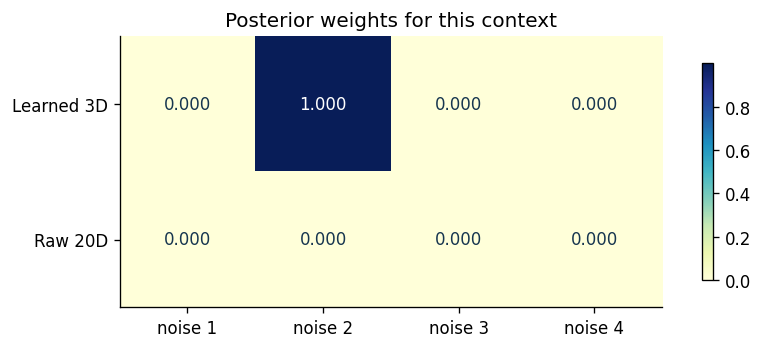

In [10]:
_, diagnostics = current_model.parents["j"].predict_arm_means(**inputs, return_diagnostics=True)
joint = diagnostics["joint_weights"][0].detach().cpu().numpy()
np.testing.assert_allclose(joint.sum(), 1.0, atol=1e-12)
fig, ax = plt.subplots(figsize=(7.4, 2.8), constrained_layout=True)
im = ax.imshow(joint, cmap="YlGnBu", vmin=0)
ax.set(xticks=range(4), xticklabels=["noise 1","noise 2","noise 3","noise 4"],
       yticks=[0,1], yticklabels=["Learned 3D", "Raw 20D"], title="Posterior weights for this context")
for row in range(2):
    for col in range(4):
        ax.text(col, row, f"{joint[row,col]:.3f}", ha="center", va="center",
                color="white" if joint[row,col] > joint.max()*.6 else "#17364f")
fig.colorbar(im, ax=ax, shrink=.8)
show(fig)


这张图的八个数加起来等于 1。它们表示**本次观测证据下，各表示／噪声组合的相对权重**。
它们不是因果效应，也不是“每个学生属于某一类”的概率；换一份观测输入，权重可以变化。


## 10 · 四个响应怎样变成三种效应？

本篇的三种对比与代码的公开入口完全一致：

$$\operatorname{Direct}_i=\mu_i(1,0)-\mu_i(0,0),$$
$$\operatorname{Spillover}_i=\mu_i(1,1)-\mu_i(1,0),$$
$$\operatorname{Total}_i=\mu_i(1,1)-\mu_i(0,0).$$

Direct 固定同伴为低暴露，只改变本人处理。Spillover 固定本人已处理，只改变同伴状态，
所以这里具体指 **treated spillover**。Total 同时改变两者。
如果固定本人未处理，用 $\mu_i(0,1)-\mu_i(0,0)$，那是另一种溢出对比，不是当前表里的 Spillover。

由于对比路径首尾相接，总有 `Total = Direct + Spillover`。
每个节点都有一组三个 ITE；再对全部 $N$ 个节点平均得到 ATE：

$$\widehat{\operatorname{ATE}}_k=\frac1N\sum_{i=1}^{N}\widehat{\operatorname{ITE}}_{ik}.$$

下面把节点 0 的四个响应画出来，再对照三种相减操作。


效应,节点真值,节点预测,全体 ATE 真值,全体 ATE 预测
Direct,-0.0405,-0.7995,-0.5040,-1.0084
Spillover,-0.0829,-0.1277,-0.3800,-0.2524
Total,-0.1234,-0.9272,-0.8840,-1.2608


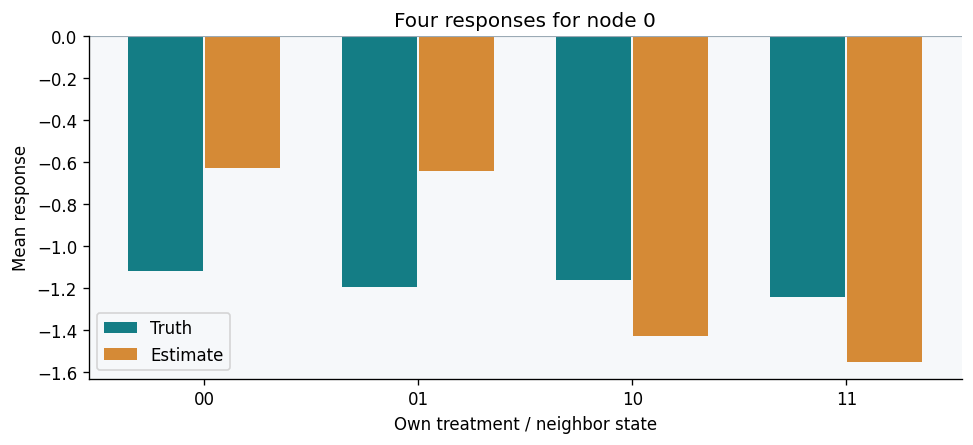

In [11]:
pred_ite, true_ite = effects(pred_mu), effects(truth_mu)
pred_ate, true_ate = pred_ite.mean(0), true_ite.mean(0)
np.testing.assert_allclose(pred_ite[:,2], pred_ite[:,0]+pred_ite[:,1], atol=1e-12)
node = FOCAL_NODE
table(pd.DataFrame({"效应": EFFECTS, "节点真值": true_ite[node], "节点预测": pred_ite[node],
                    "全体 ATE 真值": true_ate, "全体 ATE 预测": pred_ate}))
fig, ax = plt.subplots(figsize=(8,3.6), constrained_layout=True)
positions = np.arange(4)
ax.bar(positions-.18, truth_mu[node], .35, label="Truth", color=COLORS[0])
ax.bar(positions+.18, pred_mu[node], .35, label="Estimate", color=COLORS[1])
ax.set(xticks=positions, xticklabels=["00","01","10","11"], xlabel="Own treatment / neighbor state",
       ylabel="Mean response", title=f"Four responses for node {node}")
ax.axhline(0, color="#9baab5", lw=.7)
ax.legend()
show(fig)


## 11 · 预测得准不准：ITE 与 ATE 要分别看

ITE 关注每个节点的估计；本篇对一份任务计算

$$\operatorname{RMSE}_{\mathrm{ITE},k}=
\sqrt{\frac1N\sum_i(\widehat{\operatorname{ITE}}_{ik}-\operatorname{ITE}_{ik})^2}.$$

ATE 关注全体平均效应。一份任务下展示 ATE 的真值、预测、带符号误差和绝对误差即可；
跨任务的 ATE RMSE 需要对多个重复和机制聚合，不能用这一份任务代替。
节点误差有可能正负抵消，所以 ATE 接近真值并不自动意味着每个节点也预测准确。

下面散点图的每一个点对应一个节点，横轴是真值，纵轴是估计。越接近虚线越好。
三列分别对应 Direct、Spillover、Total，均使用本 notebook 刚刚算出的结果。


效应,ITE RMSE（本任务）,ATE 真值,ATE 预测,ATE 误差,ATE 绝对误差
Direct,0.5680,-0.5040,-1.0084,-0.5044,0.5044
Spillover,0.2003,-0.3800,-0.2524,0.1276,0.1276
Total,0.4760,-0.8840,-1.2608,-0.3768,0.3768


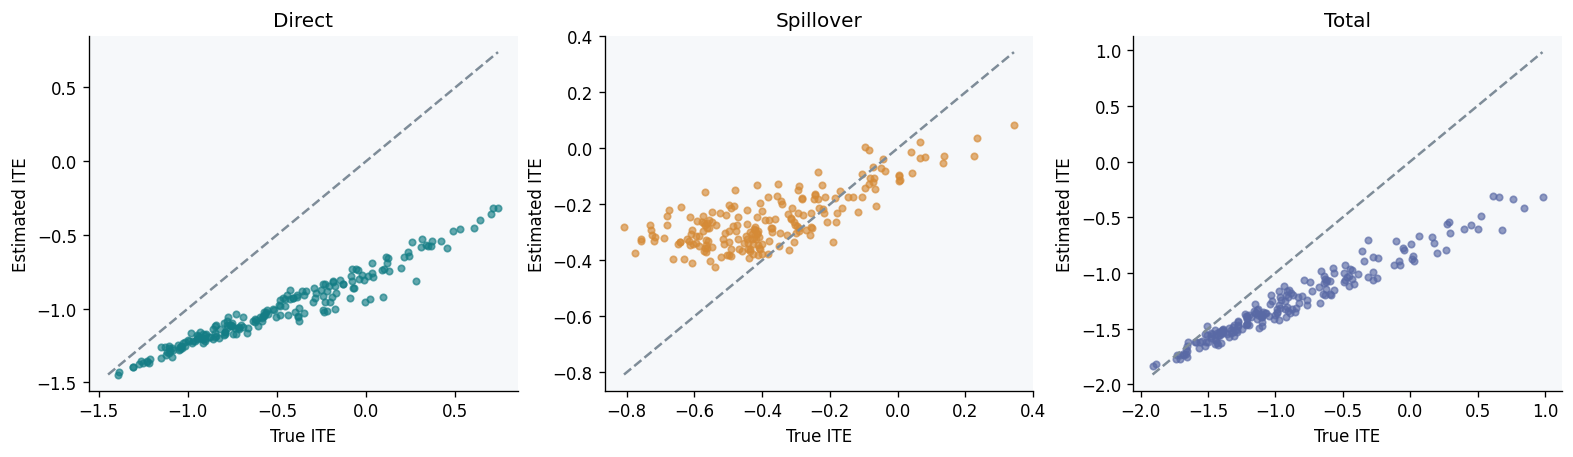

In [12]:
metrics = pd.DataFrame({"效应": EFFECTS,
    "ITE RMSE（本任务）": np.sqrt(np.mean((pred_ite-true_ite)**2, axis=0)),
    "ATE 真值": true_ate, "ATE 预测": pred_ate,
    "ATE 误差": pred_ate-true_ate, "ATE 绝对误差": np.abs(pred_ate-true_ate)})
table(metrics)
fig, axes = plt.subplots(1,3,figsize=(13,3.7), constrained_layout=True)
for k, ax in enumerate(axes):
    ax.scatter(true_ite[:,k], pred_ite[:,k], s=15, alpha=.65, color=COLORS[k])
    lo = min(true_ite[:,k].min(), pred_ite[:,k].min())
    hi = max(true_ite[:,k].max(), pred_ite[:,k].max())
    ax.plot([lo,hi],[lo,hi],"--",color="#7e8c98")
    ax.set(title=EFFECTS[k], xlabel="True ITE", ylabel="Estimated ITE")
show(fig)


## 12 · 选取 20、50、100 个结果，会发生什么？

现在固定同一张图、同一份机制、同一次处理和噪声，只改变选入推断的结果数量。
每次都预测全部 200 个节点，真值保持相同，因此这里比较的是“用于推断的观测数量变化”的影响。

通常更多观测有助于减少不确定性，但**某一个具体任务的误差不保证逐点单调下降**。
这张小图用于理解操作，不是一个经过多机制统计检验的学习曲线结论。


M,effect,ITE RMSE,ATE absolute error
20,Direct,0.7113,0.6970
20,Spillover,0.2204,0.1479
20,Total,0.5882,0.5491
50,Direct,0.5680,0.5044
50,Spillover,0.2003,0.1276
50,Total,0.4760,0.3768
100,Direct,0.4214,0.3741
100,Spillover,0.2535,0.2075
100,Total,0.2730,0.1666


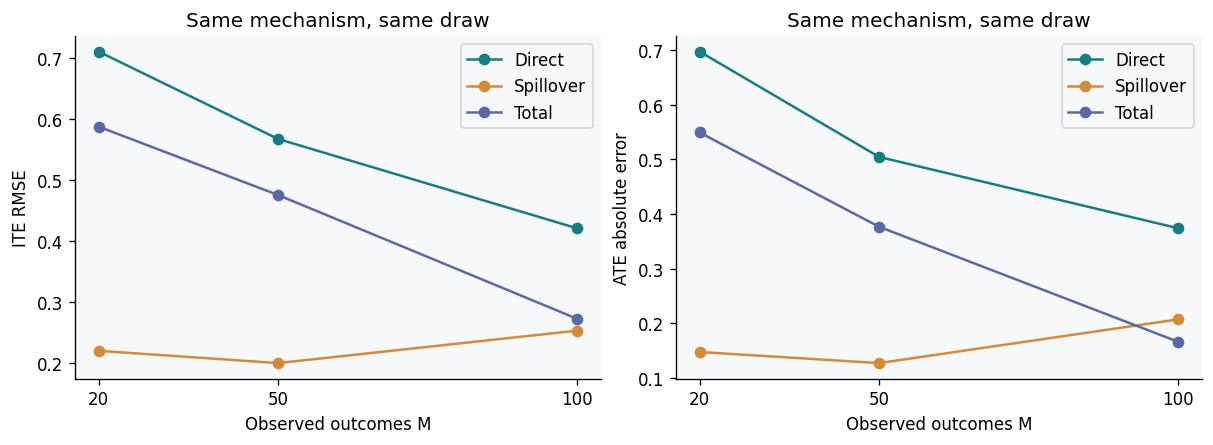

In [13]:
mask_scores = []
for row in observed_rows:
    factual = {key: value.numpy().copy() for key,value in row["batch"].items()}
    mu = current_model.predict_arm_means(**factual)
    error = effects(mu)-true_ite
    for k,name in enumerate(EFFECTS):
        mask_scores.append({"M":row["m_observed"], "effect":name,
                            "ITE RMSE":float(np.sqrt(np.mean(error[:,k]**2))),
                            "ATE absolute error":float(abs(error[:,k].mean()))})
mask_scores = pd.DataFrame(mask_scores)
table(mask_scores)
fig, axes = plt.subplots(1,2,figsize=(10,3.6), constrained_layout=True)
for name in EFFECTS:
    data = mask_scores[mask_scores["effect"] == name]
    axes[0].plot(data["M"],data["ITE RMSE"],"o-",label=name)
    axes[1].plot(data["M"],data["ATE absolute error"],"o-",label=name)
for ax,title in zip(axes,["ITE RMSE", "ATE absolute error"]):
    ax.set(xticks=[20,50,100],xlabel="Observed outcomes M",ylabel=title,title="Same mechanism, same draw")
    ax.legend()
show(fig)


## 13 · 为什么还要和基线比较？

只看 iPFN 的结果，无法知道复杂模型是否有必要。基线提供不同的参照：
设计型估计利用已知随机处理设计，线性调整使用简单回归，核方法提供另一类非线性估计。

下表说明默认快速基线。全部方法接收**同一份五数组输入**，评分使用同一份真值。

| 名字 | 大致思路 | 当前实现返回哪些目标 |
|---|---|---|
| `j` | 冻结图环境表示 + 高斯后验 | 四响应、ITE、ATE |
| `kernel-old` / `kernel-new` | 两个固定核／先验模型 | 四响应、ITE、ATE |
| `ht` / `hajek` | 按设计概率加权 | ATE；不提供节点 ITE |
| `f` / `lin` | 原始 20 维协变量的回归调整 | ATE，取决于可估计性 |
| `f-z2` / `lin-z2` | 固定二维变换后的回归调整 | ATE，取决于可估计性 |
| `non-interference` | 忽略干扰的线性回归 | 依其无干扰模型返回效应；spillover 被设为 0 |

少量结果可能导致某些处理臂缺乏观测，或回归矩阵秩不足。
因此，**不支持的目标保留为 NaN 和 false 支持标记，不能填成零后参加比较**。
特别地，“某方法不支持 spillover”和“无干扰模型把 spillover 定义成零”是两种不同情况。

下面实际运行 10 个默认方法，只展示同一任务的描述性比较。
HINet、TNet、HyperSCI 需要在线拟合；CausalPFN 需要另附外部权重，本篇的快速流程不执行这些昂贵或额外依赖的分支。


In [14]:
config = configuration()  # 同时核对冻结资源的 hash
methods = load_methods(list(DEFAULT_METHODS), config)
baseline_rows, baseline_results = [], {}
fit_seed = 651013 + 1000*FAMILY_ID + 100*MECHANISM_ID + REPEAT_ID
for name, estimator in methods.items():
    started = time.perf_counter()
    result = predict_method(name, estimator, inputs, fit_seed)
    seconds = time.perf_counter()-started
    baseline_results[name] = result
    for k,effect_name in enumerate(EFFECTS):
        supported_ite, supported_ate = bool(result["ite_supported"][k]), bool(result["ate_supported"][k])
        baseline_rows.append({"method":name, "effect":effect_name,
            "ITE 支持":supported_ite, "ATE 支持":supported_ate,
            "ITE RMSE":float(np.sqrt(np.mean((result["ite_effects"][:,k]-true_ite[:,k])**2))) if supported_ite else np.nan,
            "ATE 绝对误差":float(abs(result["ate_effects"][k]-true_ate[k])) if supported_ate else np.nan,
            "本次调用秒数":seconds})
baseline_table = pd.DataFrame(baseline_rows)
np.testing.assert_allclose(baseline_results["j"]["arm_means"], pred_mu, rtol=1e-10,atol=1e-10)
table(baseline_table)


method,effect,ITE 支持,ATE 支持,ITE RMSE,ATE 绝对误差,本次调用秒数
j,Direct,True,True,0.5680,0.5044,0.0135
j,Spillover,True,True,0.2003,0.1276,0.0135
j,Total,True,True,0.4760,0.3768,0.0135
ht,Direct,False,True,—,0.3391,0.0037
ht,Spillover,False,True,—,1.1470,0.0037
ht,Total,False,True,—,1.4860,0.0037
hajek,Direct,False,True,—,0.4818,0.0023
hajek,Spillover,False,True,—,0.7155,0.0023
hajek,Total,False,True,—,1.1973,0.0023
f,Direct,False,True,—,0.7344,0.0043


表里的横杠表示该目标不可用。不能因为某个方法缺少困难案例，就把它与有完整支持的方法作不加说明的整体排名。
“本次调用秒数”是当前电脑的一次在线耗时，模型加载发生在计时之前。

`benchmark.py --cohort full` 的配置为 **7 类 × 8 个机制 × 12 次处理／噪声重复 × 3 个观测数量 = 2016 个上下文**。
这些上下文来自 56 个独立机制；同一机制下的重复具有共同的响应规律。解释汇总误差时应考虑这层结构。本篇只运行一个上下文的快速比较。


## 14 · 小图模拟例子：为什么还多了一个组合步骤？

当前预测入口包含一个固定分支：

- $N<50$ 且使用全部节点的结果：采用校准后的 J、旧核、新核的平均响应组合；
- 其他情况：返回冻结 J 的预测。

组合公式为

$$\widehat\mu=0.25\widehat\mu_{J,\mathrm{cal}}+
0.375\widehat\mu_{K1,\mathrm{cal}}+0.375\widehat\mu_{K2,\mathrm{cal}}.$$

各组件先按固定参数调整先验强度、噪声尺度和表示权重，再把四臂均值按相同权重相加。
参数保存在 `regional_selected.json`。组合的是响应均值，不能直接把它解释为某一个高斯先验的完整后验分布。

下面另建一个 **10 个节点的环形图**，取前面合成机制中前 10 个节点的特征和隐藏表示，沿用同一组模拟系数。
因为图变了，需要重新计算邻居聚合项，再用同一个 `structural_outcome` 函数生成结果。
这只是演示小图分支的合成例子：所有结果都由模拟器生成，并选取全部 10 个结果用于推断。


效应,组合 ATE,校准 J 的 ATE,校准旧核 ATE,校准新核 ATE
Direct,-0.2047,-0.3032,-0.2135,-0.1302
Spillover,-0.3482,-0.1286,-0.5857,-0.2570
Total,-0.5528,-0.4318,-0.7992,-0.3873


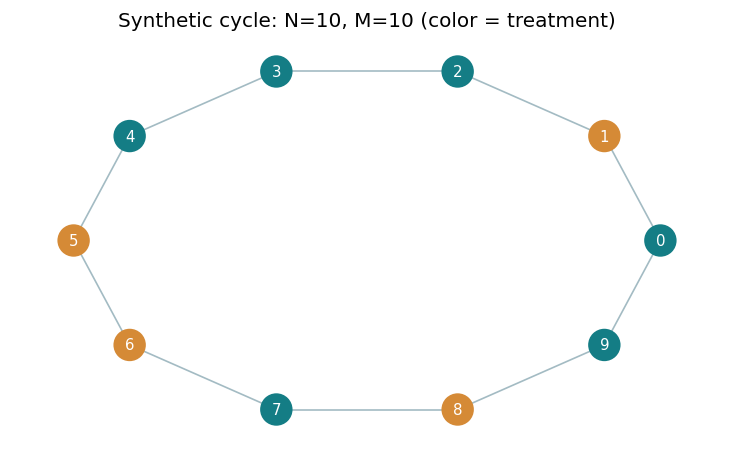

In [15]:
from types import SimpleNamespace
from pfn_social.phase3_hierarchical import _components

small_n = 10
small_graph = nx.cycle_graph(small_n)
small_a = nx.to_numpy_array(small_graph, dtype=np.float32)
small_x, small_h = X[:small_n].copy(), h[:small_n].copy()
small_sim = SimpleNamespace(adjacency=small_a, h=small_h, coefficients=beta.copy(),
    components=_components(small_a, small_h, beta))
small_rng = np.random.default_rng(2026)
small_t = small_rng.binomial(1, .5, small_n).astype(np.float32)
small_y = (structural_outcome(small_sim, small_t) + small_rng.normal(0, .5, small_n)).astype(np.float32)
small_inputs = dict(x=small_x, adjacency=small_a, treatment=small_t,
    observed_indices=np.arange(small_n, dtype=np.int64), outcomes_observed=small_y)
validate_factual_inputs(**small_inputs)
assert regional_gate(small_inputs)
small_mu = current_model.predict_arm_means(**small_inputs)
component_mu = {name: part.predict_arm_means(**small_inputs)
                for name, part in current_model.components.items()}
weighted_mu = .25*component_mu["j"] + .375*component_mu["kernel-old"] + .375*component_mu["kernel-new"]
np.testing.assert_allclose(small_mu, weighted_mu, rtol=1e-12, atol=1e-12)
table(pd.DataFrame({"效应": EFFECTS, "组合 ATE": effects(small_mu).mean(0),
    "校准 J 的 ATE": effects(component_mu["j"]).mean(0),
    "校准旧核 ATE": effects(component_mu["kernel-old"]).mean(0),
    "校准新核 ATE": effects(component_mu["kernel-new"]).mean(0)}))

fig, ax = plt.subplots(figsize=(6, 3.7), constrained_layout=True)
nx.draw_networkx(small_graph, pos=nx.circular_layout(small_graph), ax=ax,
    node_color=[COLORS[int(t)] for t in small_t], font_color="white", font_size=9,
    node_size=340, edge_color="#a3bbc3")
ax.set_title("Synthetic cycle: N=10, M=10 (color = treatment)")
ax.axis("off")
show(fig)
np.savez_compressed(RESULTS / "small_input.npz", **small_inputs)


本节核对的是代码中的分支条件和加权关系。表里的 ATE 都是模型预测；这一小例子用于理解调用过程，不用于给方法作性能排名。


## 15 · 回到命令行：Notebook 与脚本怎样对应？

如果已经把五个观测数组保存为 `.npz` 文件，可以直接运行：

```bash
cd code/sparse_j
python predict_current.py --input /path/to/factual_input.npz --output prediction.npz
python benchmark.py --output ../../my_results/one_context
```

将 `/path/to/factual_input.npz` 换成自己的输入文件路径。五个键和数组形状见第 07 节；第 07 节的 `np.savez_compressed` 展示了如何保存。
`benchmark.py` 自行生成合成数据，要求使用全新的输出目录，默认执行单个上下文的十个快速方法。

预测文件包含 `arm_means[N,4]`、`ite[N,3]`、`ate[3]`。
基准脚本使用字段 `ite_effects`、`ate_effects` 和三个 `*_supported` 标记，效应定义相同。

下面实际执行两个预测命令，分别传入前面生成的 200 节点与 10 节点输入，核对命令行与 notebook 预测是否一致。
浮点比较使用 $2\times10^{-6}$ 的容差。


In [16]:
import subprocess
comparison_rows = []
for label, filename, reference_mu in [
    ("N200 / M50", "factual_input.npz", pred_mu),
    ("N10 / M10", "small_input.npz", small_mu)]:
    destination = RESULTS / ("cli_" + filename)
    completed = subprocess.run([sys.executable, str(CODE / "predict_current.py"),
        "--input", str(RESULTS / filename), "--output", str(destination)],
        cwd=str(CODE), capture_output=True, text=True, check=True)
    reference = dict(arm_means=reference_mu, ite=effects(reference_mu), ate=effects(reference_mu).mean(0))
    with np.load(destination, allow_pickle=False) as got:
        for key, value in reference.items():
            np.testing.assert_allclose(got[key], value, rtol=2e-6, atol=2e-6)
        difference = float(np.max(np.abs(got["arm_means"] - reference_mu)))
    comparison_rows.append({"例子": label, "两种调用最大绝对差": difference, "结果": "一致"})
    print(completed.stdout.strip())
    if completed.stderr.strip():
        print(completed.stderr.strip())
table(pd.DataFrame(comparison_rows), digits=10)


Current iPFN: N=200 m=50; route=frozen J


Current iPFN: N=10 m=10; route=regional calibrated ensemble


例子,两种调用最大绝对差,结果
N200 / M50,0.0000000000,一致
N10 / M10,0.0000000000,一致


## 16 · 怎样继续读源码？

这份代码提供模型推断、合成数据生成和基线评测。模型权重、特征变换、核先验以及运行配置随代码保存，
可以直接运行“生成观测 → 预测四状态响应 → 计算效应 → 对照模拟真值评测”。

先沿这条调用链阅读：

```text
predict_current.load_current_model()
    → predict.load_selected_model()
    → SparseFrozenGaussian.predict_arm_means(五个观测数组)
    → 四臂均值 → 三种 ITE → 对 N 个节点平均得到 ATE
```

小图且全观测时进入 `RegionalArmEnsemble` 的组合分支。
基线比较从 `benchmark.py` 的 `load_methods`、`predict_method` 进入。

要理解推断细节，可以按 **validate_factual_inputs → design → gaussian_sparse_component → 权重加总** 的顺序阅读。
始终对照数组形状：用于条件化的事实行为 $M$，查询节点为 $N$。


## 17 · 学完以后，应该能够自己解释什么？

1. **我们的研究问题是什么？** 在存在同伴影响时，估计每个节点及总体的直接、溢出与总效应。观测结果可以按实验设置选取部分或全部节点。
2. **为什么需要图？** 它告诉我们谁影响谁，从而决定邻居聚合、暴露和状态查询。
3. **为什么四个臂不等于四次真实观测？** 一个节点在一次分配中只有一个事实结果，其余状态响应由模型估计；模拟器才知道全部真值。
4. **用于推断的结果数 $M$ 与查询节点数 $N$ 有什么关系？** 所有节点的特征、处理和图结构已知；选定的 $M$ 个结果用于条件化，全部 $N$ 个节点用于查询；$M$ 可以等于 $N$。
5. **iPFN 在线是否训练网络？** 当前 J 及核参数冻结，在线执行后验条件化。深度基线有自己的在线拟合流程，不能混为一谈。
6. **为什么 ITE 好与 ATE 好不完全相同？** ATE 会平均节点误差，正负误差可能抵消。
7. **看一份任务能否证明方法最优？** 不能。它帮助理解计算；性能结论要看预先定义的多机制评测、支持范围与统计不确定性。

可以动手做三件小练习：

- 把第 02 节 `FAMILY_ID` 从 0 改成 3，从该节向后重新运行，看看 ER 型图、暴露与误差怎样变化。
- 把 `FOCAL_NODE` 改为另一个节点，比较它的四个响应与三种效应。
- 在第 12 节比较三个 $M$ 的结果，用自己的话说明“信息增加”与“单个任务误差单调下降”为什么不是一回事。

所有图、数字和误差表以实际运行输出为准。做练习后，它们会更新为新配置的结果。
Notebook 负责讲解、调用和可视化；模型推断由 `code/sparse_j/` 中的实现完成。
